In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import seaborn as sns
from matplotlib.ticker import MaxNLocator
import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",   # Prefer if installed
        "Liberation Serif",  # Common on Ubuntu / Debian
        "Nimbus Roman",      # Common with TeX / Ghostscript
        "DejaVu Serif"       # Matplotlib fallback
    ],
    "mathtext.fontset": "stix",       # Math symbols closer to Times
    "axes.unicode_minus": False,
})

import os
import sys
from pathlib import Path

# Utils lives under SynEnergy/. This notebook is Analysis/Figure/Motivation/
# Prefer the notebook file path (Cursor/VS Code); fall back to cwd.
_nb_file = globals().get("__vsc_ipynb_file__")
_nb_dir = Path(_nb_file).resolve().parent if _nb_file else Path.cwd().resolve()
synenergy_root = (_nb_dir / ".." / ".." / ".." / "SynEnergy").resolve()
if not (synenergy_root / "Utils").is_dir():
    # cwd may already be SysEnergy (or another parent)
    synenergy_root = None
    for p in [_nb_dir, *_nb_dir.parents]:
        cand = p / "SynEnergy"
        if (cand / "Utils").is_dir():
            synenergy_root = cand
            break
if synenergy_root is None:
    raise RuntimeError(f"Cannot locate SynEnergy/Utils from nb_dir={_nb_dir}, cwd={Path.cwd()}")
if str(synenergy_root) not in sys.path:
    sys.path.insert(0, str(synenergy_root))

import torch
from Utils.context_fid import Context_FID
from Utils.predictive_metric import predictive_score_metrics
import Utils.extreme_anomaly_metric as extreme_anomaly_metric
from Utils.extreme_anomaly_metric import (
    extreme_anomaly_score_metrics,
    extreme_reconstruction_score_metrics,
)


pd.set_option("display.max_rows", None)         # Show all rows
pd.set_option("display.max_columns", None)      # Show all columns
pd.set_option("display.width", None)            # No fixed-width wrap
pd.set_option("display.max_colwidth", None)     # Do not truncate cell values
pd.set_option("display.expand_frame_repr", False)  # Prefer single-line frames

In [3]:
ori1 = np.load('../../../SynEnergy/OUTPUT/power1/origin_data_norm_power1.npy')
ori2 = np.load('../../../SynEnergy/OUTPUT/power2/origin_data_norm_power2.npy')
ori3 = np.load('../../../SynEnergy/OUTPUT/power3/origin_data_norm_power3.npy')
ori4 = np.load('../../../SynEnergy/OUTPUT/power4/origin_data_norm_power4.npy')
ori5 = np.load('../../../SynEnergy/OUTPUT/power5/origin_data_norm_power5.npy')

gen11 = np.load('../../../SynEnergy/OUTPUT/power1/generate_data_norm_power1.npy')
gen21 = np.load('../../../SynEnergy/OUTPUT/power2/generate_data_norm_power2.npy')
gen31 = np.load('../../../SynEnergy/OUTPUT/power3/generate_data_norm_power3.npy')
gen41 = np.load('../../../SynEnergy/OUTPUT/power4/generate_data_norm_power4.npy')
gen51 = np.load('../../../SynEnergy/OUTPUT/power5/generate_data_norm_power5.npy')


gen12 = np.load('../../../SynEnergy/OUTPUT/power_controlnet1/generate_data_norm_power_controlnet1.npy')
gen22 = np.load('../../../SynEnergy/OUTPUT/power_controlnet2/generate_data_norm_power_controlnet2.npy')
gen32 = np.load('../../../SynEnergy/OUTPUT/power_controlnet3/generate_data_norm_power_controlnet3.npy')    
gen42 = np.load('../../../SynEnergy/OUTPUT/power_controlnet4/generate_data_norm_power_controlnet4.npy')
gen52 = np.load('../../../SynEnergy/OUTPUT/power_controlnet5/generate_data_norm_power_controlnet5.npy')


gen13 = np.load('../../../SynEnergy/OUTPUT//power_heavy1/generate_data_norm_power_heavy1.npy')
gen23 = np.load('../../../SynEnergy/OUTPUT//power_heavy2/generate_data_norm_power_heavy2.npy')
gen33 = np.load('../../../SynEnergy/OUTPUT//power_heavy3/generate_data_norm_power_heavy3.npy')
gen43 = np.load('../../../SynEnergy/OUTPUT//power_heavy4/generate_data_norm_power_heavy4.npy')
gen53 = np.load('../../../SynEnergy/OUTPUT//power_heavy5/generate_data_norm_power_heavy5.npy')

gen14 = np.load('../../../SynEnergy/OUTPUT/power_heavy_controlnet1/generate_data_norm_power_heavy_controlnet1.npy')
gen24 = np.load('../../../SynEnergy/OUTPUT/power_heavy_controlnet2/generate_data_norm_power_heavy_controlnet2.npy')
gen34 = np.load('../../../SynEnergy/OUTPUT/power_heavy_controlnet3/generate_data_norm_power_heavy_controlnet3.npy')
gen44 = np.load('../../../SynEnergy/OUTPUT/power_heavy_controlnet4/generate_data_norm_power_heavy_controlnet4.npy')
gen54 = np.load('../../../SynEnergy/OUTPUT/power_heavy_controlnet5/generate_data_norm_power_heavy_controlnet5.npy')

## Figure 1

In [4]:
def zero_rate(arr):
    """全数组中值为 0 的比例"""
    arr = np.asarray(arr)
    return (arr == -1).sum() / arr.size

rows = []
for i in range(1, 6):
    rows.append({
        "run": f"power{i}",
        "ori_zero_rate": zero_rate(globals()[f"ori{i}"]),
        "gen_diffusionts_zero_rate": zero_rate(globals()[f"gen{i}1"]),
        "gen_controlnet_zero_rate": zero_rate(globals()[f"gen{i}2"]),
        "gen_heavy_zero_rate": zero_rate(globals()[f"gen{i}3"]),
        "gen_heavy_controlnet_zero_rate": zero_rate(globals()[f"gen{i}4"]),
    })

df_zero_rate = pd.DataFrame(rows)

# 追加平均行
mean_row = {
    "run": "mean",
    "ori_zero_rate": df_zero_rate["ori_zero_rate"].mean(),
    "gen_diffusionts_zero_rate": df_zero_rate["gen_diffusionts_zero_rate"].mean(),
    "gen_controlnet_zero_rate": df_zero_rate["gen_controlnet_zero_rate"].mean(),
    "gen_heavy_zero_rate": df_zero_rate["gen_heavy_zero_rate"].mean(),
    "gen_heavy_controlnet_zero_rate": df_zero_rate["gen_heavy_controlnet_zero_rate"].mean(),
}
df_zero_rate = pd.concat([df_zero_rate, pd.DataFrame([mean_row])], ignore_index=True)

df_zero_rate

,run,ori_zero_rate,gen_diffusionts_zero_rate,gen_controlnet_zero_rate,gen_heavy_zero_rate,gen_heavy_controlnet_zero_rate
0,power1,0.091353,0.032268,0.040229,0.045333,0.048054
1,power2,0.091353,0.050696,0.079427,0.057962,0.048696
2,power3,0.091353,0.060145,0.054864,0.062276,0.034234
3,power4,0.091353,0.049538,0.061235,0.031596,0.065880
4,power5,0.091353,0.049156,0.045319,0.061801,0.047318
5,mean,0.091353,0.048360,0.056215,0.051793,0.048837


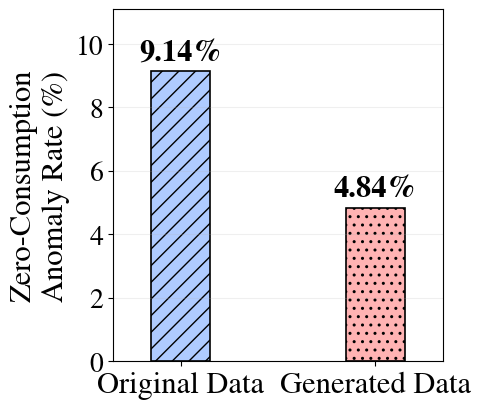

In [58]:
import numpy as np
import matplotlib.pyplot as plt

# 已知结果
ori_zero_rate = 9.14
gen_zero_rate = 4.84

rates = [ori_zero_rate, gen_zero_rate]
labels = ["Original Data", "Generated Data"]

fig, ax = plt.subplots(figsize=(5, 4.2))

# 手动设置柱子中心位置：让两个柱子更靠近
x = np.array([0.0, 0.72])

# 更窄的柱宽
bar_width = 0.22

bars = ax.bar(
    x,
    rates,
    width=bar_width,
    color=["#AFCBFF", "#FFB3B3"],   # 浅蓝、浅红
    edgecolor="black",
    linewidth=1.2
)

# 添加花纹
bars[0].set_hatch("//")   # 斜杠花纹
bars[1].set_hatch("..")   # 点花纹

# 柱顶数值
for xi, yi in zip(x, rates):
    ax.text(
        xi,
        yi + 0.18,
        f"{yi:.2f}%",
        ha="center",
        va="bottom",
        fontsize=22,
        fontweight="bold"
    )

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=22)

ax.set_ylabel("Zero-Consumption\nAnomaly Rate (%)", fontsize=22)
ax.tick_params(axis="y", labelsize=20)

ax.set_ylim(0, 11.1)
ax.grid(axis="y", alpha=0.2)

# 控制左右留白
ax.set_xlim(-0.25, 0.97)

plt.tight_layout()
plt.savefig(f"../../../Analysis/Plot/Motivation/anomalypreserve/zero_rate_diffusionTS.png", dpi=300)
plt.show()

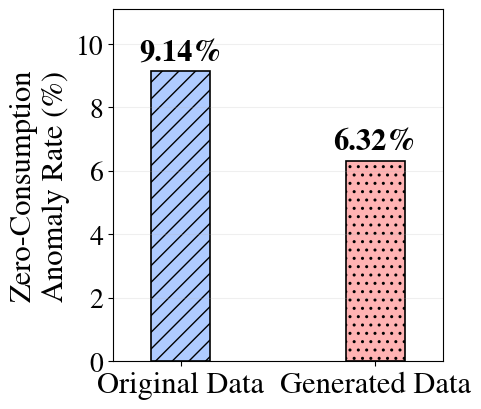

In [57]:
import numpy as np
import matplotlib.pyplot as plt

# 已知结果
ori_zero_rate = 9.14
gen_zero_rate = 6.32

rates = [ori_zero_rate, gen_zero_rate]
labels = ["Original Data", "Generated Data"]

fig, ax = plt.subplots(figsize=(5, 4.2))

# 手动设置柱子中心位置：让两个柱子更靠近
x = np.array([0.0, 0.72])

# 更窄的柱宽
bar_width = 0.22

bars = ax.bar(
    x,
    rates,
    width=bar_width,
    color=["#AFCBFF", "#FFB3B3"],   # 浅蓝、浅红
    edgecolor="black",
    linewidth=1.2
)

# 添加花纹
bars[0].set_hatch("//")   # 斜杠花纹
bars[1].set_hatch("..")   # 点花纹

# 柱顶数值
for xi, yi in zip(x, rates):
    ax.text(
        xi,
        yi + 0.18,
        f"{yi:.2f}%",
        ha="center",
        va="bottom",
        fontsize=22,
        fontweight="bold"
    )

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=22)

ax.set_ylabel("Zero-Consumption\nAnomaly Rate (%)", fontsize=22)
ax.tick_params(axis="y", labelsize=20)

ax.set_ylim(0, 11.1)
ax.grid(axis="y", alpha=0.2)

# 控制左右留白
ax.set_xlim(-0.25, 0.97)

plt.tight_layout()
plt.savefig(f"../../../Analysis/Plot/Motivation/anomalypreserve/zero_rate_controlnet.png", dpi=300)
plt.show()

# Figure 2

In [6]:
from Experiment.Result_Analysis.anomaly_distribution_metrics import (
    _standardized_residual_batch,
    DEFAULT_TAU,
    DEFAULT_NUM_DAYS,
    DEFAULT_SLOTS_PER_DAY,
    DEFAULT_RESIDUAL_EPS,
    DEFAULT_MIN_SCALE,
)
def to_metric_first_space(data):
    data = np.asarray(data, dtype=np.float64)
    if data.ndim == 2:
        data = data[..., None]
    return _standardized_residual_batch(
        data,
        DEFAULT_NUM_DAYS,        # 30
        DEFAULT_SLOTS_PER_DAY,   # 6
        DEFAULT_RESIDUAL_EPS,    # 1e-6
        DEFAULT_MIN_SCALE,       # 1.0
        True,                    # use_mad_consistency
    )
# 示例
r_ori1 = to_metric_first_space(ori1) 
r_ori2 = to_metric_first_space(ori2)
r_ori3 = to_metric_first_space(ori3)
r_ori4 = to_metric_first_space(ori4)
r_ori5 = to_metric_first_space(ori5)

r_gen11 = to_metric_first_space(gen11)
r_gen21 = to_metric_first_space(gen21)
r_gen31 = to_metric_first_space(gen31)
r_gen41 = to_metric_first_space(gen41)
r_gen51 = to_metric_first_space(gen51)

r_gen12 = to_metric_first_space(gen12)
r_gen22 = to_metric_first_space(gen22)
r_gen32 = to_metric_first_space(gen32)
r_gen42 = to_metric_first_space(gen42)
r_gen52 = to_metric_first_space(gen52)

r_gen13 = to_metric_first_space(gen13)
r_gen23 = to_metric_first_space(gen23)
r_gen33 = to_metric_first_space(gen33)
r_gen43 = to_metric_first_space(gen43)
r_gen53 = to_metric_first_space(gen53)

r_gen14 = to_metric_first_space(gen14)
r_gen24 = to_metric_first_space(gen24)
r_gen34 = to_metric_first_space(gen34)
r_gen44 = to_metric_first_space(gen44)
r_gen54 = to_metric_first_space(gen54)


Anomaly threshold: |r| > TAU = 0.11283458769321442  (same as Metric_First)


,series,n_events,mean_duration,median_duration
0,ori,504220,1.783825,1.0
1,diffusionts,288574,1.640106,1.0
2,controlnet,460435,1.806752,1.0
3,heavy,338132,1.550643,1.0
4,heavy_controlnet,508527,1.724762,1.0


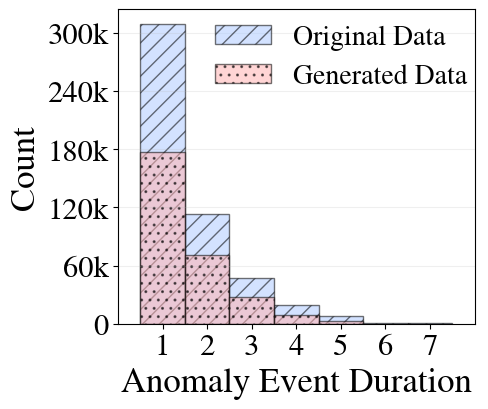

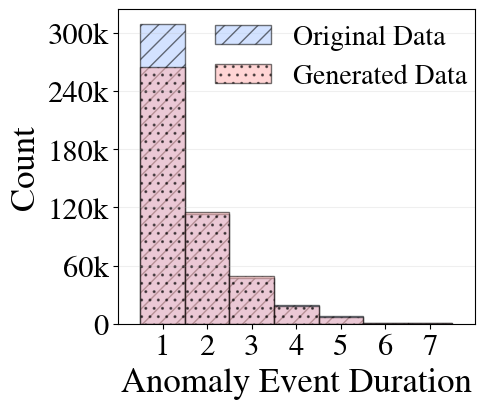

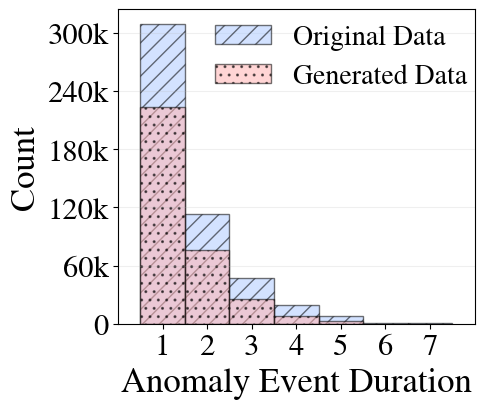

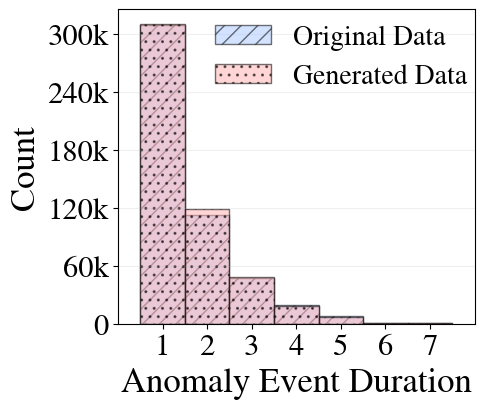

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

# 与 Metric_First 一致
TAU = np.nanquantile(np.abs(r_ori1), 0.90)

def to_2d_r(arr):
    """(N, T, 1) or (N, T) residual -> (N, T)"""
    return np.asarray(arr, dtype=float).squeeze(-1)

def residual_anomaly_mask(r_batch, tau=TAU):
    """|r| > tau"""
    return np.abs(to_2d_r(r_batch)) > float(tau)

def extract_event_lengths_from_mask(mask_2d):
    event_lengths = []
    for mask in mask_2d:
        padded = np.pad(mask.astype(int), (1, 1), constant_values=0)
        transitions = np.diff(padded)
        starts = np.where(transitions == 1)[0]
        ends = np.where(transitions == -1)[0]
        event_lengths.extend(ends - starts)
    return np.asarray(event_lengths, dtype=int)

def pool_residual_event_lengths(r_list, tau=TAU):
    """5 runs: pool event lengths from |r|>tau masks."""
    lengths = []
    for r in r_list:
        mask = residual_anomaly_mask(r, tau=tau)
        lengths.append(extract_event_lengths_from_mask(mask))
    return np.concatenate(lengths)


def _count_k_formatter(x, pos):
    if x == 0:
        return "0"
    if abs(x) >= 1000:
        v = x / 1000.0
        return f"{v:.0f}k" if abs(v - round(v)) < 1e-6 else f"{v:.1f}k"
    return f"{int(x)}"
def plot_duration_hist(ori_lengths, gen_lengths, title, save_path=None):
    bin_width = 1
    x_min, x_max = 0, 7
    # 中心在 1, 2, 3, ...：边界 0.5, 1.5, 2.5, ...
    bin_centers = np.arange(x_min + 1, x_max + 1, bin_width)   # 1,2,...,7
    bins = np.arange(x_min + 0.5, x_max + 0.5 + bin_width, bin_width)  # 0.5,...,7.5
    fig, ax = plt.subplots(figsize=(5, 4.2))
    ax.hist(
        ori_lengths,
        bins=bins,
        alpha=0.55,
        color="#AFCBFF",
        edgecolor="black",
        linewidth=1.0,
        hatch="//",
        label="Original Data",
    )
    ax.hist(
        gen_lengths,
        bins=bins,
        alpha=0.55,
        color="#FFB3B3",
        edgecolor="black",
        linewidth=1.0,
        hatch="..",
        label="Generated Data",
    )
    ax.set_xlim(x_min, x_max + 1)   # 略宽一点，让 7 的柱子完整显示
    ax.set_xticks(bin_centers)      # 1,2,...,7 每个都显示
    ax.set_xticklabels([str(int(x)) for x in bin_centers], fontsize=22)
    ax.set_xlabel("Anomaly Event Duration", fontsize=25)
    ax.set_ylabel("Count", fontsize=25)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6, integer=True))
    ax.yaxis.set_major_formatter(FuncFormatter(_count_k_formatter))
    ax.tick_params(axis="y", labelsize=22)
    ax.legend(loc="upper right", bbox_to_anchor=(1.05, 1.03), fontsize=20, frameon=False)
    ax.grid(axis="y", alpha=0.2)
    #ax.set_title(title, fontsize=18)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300)
    plt.show()

# ---------- 使用已转换的 residual（r_ori*, r_gen*）----------
ori_list = [globals()[f"r_ori{i}"] for i in range(1, 6)]
gen_diff_list = [globals()[f"r_gen{i}1"] for i in range(1, 6)]   # DiffusionTS
gen_cn_list = [globals()[f"r_gen{i}2"] for i in range(1, 6)]     # ControlNet
gen_heavy_list = [globals()[f"r_gen{i}3"] for i in range(1, 6)] # Heavy
gen_heavy_controlnet_list = [globals()[f"r_gen{i}4"] for i in range(1, 6)] # Heavy ControlNet

print(f"Anomaly threshold: |r| > TAU = {TAU}  (same as Metric_First)")

# pooled event lengths（5-run）
ori_event_lengths = pool_residual_event_lengths(ori_list, tau=TAU)
gen_diff_lengths = pool_residual_event_lengths(gen_diff_list, tau=TAU)
gen_cn_lengths = pool_residual_event_lengths(gen_cn_list, tau=TAU)
gen_heavy_lengths = pool_residual_event_lengths(gen_heavy_list, tau=TAU)
gen_heavy_controlnet_lengths = pool_residual_event_lengths(gen_heavy_controlnet_list, tau=TAU)

summary = pd.DataFrame({
    "series": ["ori", "diffusionts", "controlnet", "heavy", "heavy_controlnet"],
    "n_events": [len(ori_event_lengths), len(gen_diff_lengths), len(gen_cn_lengths), len(gen_heavy_lengths), len(gen_heavy_controlnet_lengths)],
    "mean_duration": [
        ori_event_lengths.mean(),
        gen_diff_lengths.mean(),
        gen_cn_lengths.mean(),
        gen_heavy_lengths.mean(),
        gen_heavy_controlnet_lengths.mean(),
    ],
    "median_duration": [
        np.median(ori_event_lengths),
        np.median(gen_diff_lengths),
        np.median(gen_cn_lengths),
        np.median(gen_heavy_lengths),
        np.median(gen_heavy_controlnet_lengths),
    ],
})
display(summary)

# 图1: Ori vs DiffusionTS
plot_duration_hist(
    ori_event_lengths,
    gen_diff_lengths,
    title=f"Ori vs DiffusionTS (|r|>{TAU}, 5-run pooled)",
    save_path="../../../Analysis/Plot/Motivation/anomalypreserve/anomaly_duration_diffusionTS.png",
)

# 图2: Ori vs ControlNet
plot_duration_hist(
    ori_event_lengths,
    gen_cn_lengths,
    title=f"Ori vs ControlNet (|r|>{TAU}, 5-run pooled)",
    save_path="../../../Analysis/Plot/Motivation/anomalypreserve/anomaly_duration_controlnet.png",
)

# 图3: Ori vs Heavy
plot_duration_hist(
    ori_event_lengths,
    gen_heavy_lengths,
    title=f"Ori vs Heavy (|r|>{TAU}, 5-run pooled)",
    #save_path="../../../Analysis/Plot/Motivation/anomalypreserve/anomaly_duration_heavy.png",
)

# 图4: Ori vs Heavy ControlNet
plot_duration_hist(
    ori_event_lengths,
    gen_heavy_controlnet_lengths,
    title=f"Ori vs Heavy ControlNet (|r|>{TAU}, 5-run pooled)",
    #save_path="../../../Analysis/Plot/Motivation/anomalypreserve/anomaly_duration_heavy_controlnet.png",
)

## Figure3

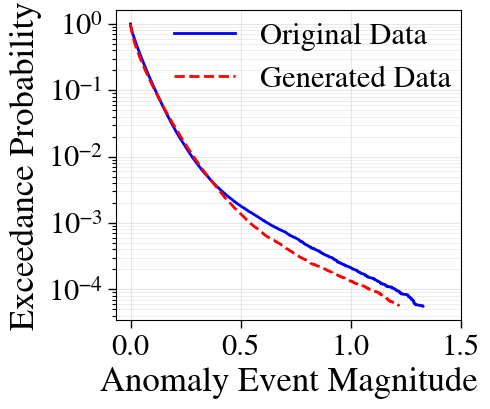

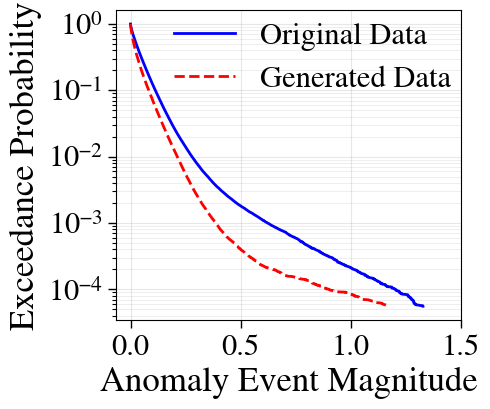

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
PLOT_DIR = "../../../Analysis/Plot/Appendix/anomalypreserve"
XLABEL = "Anomaly Event Magnitude"
YLABEL = "Exceedance Probability"
def to_2d_r(arr):
    arr = np.asarray(arr, dtype=float)
    if arr.ndim == 3 and arr.shape[-1] == 1:
        arr = arr.squeeze(-1)
    return arr
def extract_magnitudes(data):
    values = np.asarray(data, dtype=float).reshape(-1)
    values = values[np.isfinite(values)]
    return np.abs(values)
def empirical_ccdf(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return np.array([]), np.array([])
    x = np.sort(values)
    n = len(x)
    return x, (n - np.arange(n)) / n
def _stable_tail_mask(x, ccdf, display_threshold, min_p):
    return (x >= display_threshold) & (ccdf >= min_p)
def plot_residual_magnitude_ccdf(
    ori,
    gen,
    display_threshold=0.0,
    min_tail_count=100,
    xlabel=XLABEL,
    ylabel=YLABEL,
    title=None,
    save_path=None,
):
    """Plot empirical CCDF of absolute residual magnitudes (Original vs Generated)."""
    ori_mag = extract_magnitudes(ori)
    gen_mag = extract_magnitudes(gen)
    ori_x, ori_ccdf = empirical_ccdf(ori_mag)
    gen_x, gen_ccdf = empirical_ccdf(gen_mag)
    ori_min_p = min_tail_count / len(ori_mag)
    gen_min_p = min_tail_count / len(gen_mag)
    ori_mask = _stable_tail_mask(ori_x, ori_ccdf, display_threshold, ori_min_p)
    gen_mask = _stable_tail_mask(gen_x, gen_ccdf, display_threshold, gen_min_p)
    fig, ax = plt.subplots(figsize=(5, 4.2))
    ax.plot(
        ori_x[ori_mask], ori_ccdf[ori_mask],
        linewidth=2.0, color="blue", label="Original Data",
    )
    ax.plot(
        gen_x[gen_mask], gen_ccdf[gen_mask],
        linestyle="--", linewidth=2.0, color="red", label="Generated Data",
    )
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=10))
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=100))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel(xlabel, fontsize=25)
    ax.set_ylabel(ylabel, fontsize=25)
    ax.set_xticks([0, 0.5, 1.0, 1.5])
    ax.tick_params(axis="both", which="major", labelsize=22, length=6, width=1.0)
    ax.tick_params(axis="y", which="minor", length=3, width=0.8, left=True, right=False)
    ax.legend(loc="upper right", bbox_to_anchor=(1.05, 1.05), fontsize=22, frameon=False)
    ax.grid(which="major", axis="both", alpha=0.30, linewidth=0.8)
    ax.grid(which="minor", axis="y", alpha=0.30, linewidth=0.5)
    if display_threshold > 0:
        ax.set_xlim(left=display_threshold)
    if title is not None:
        ax.set_title(title, fontsize=18)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
# ---------- 每个 run 单独保存 residual（长度均为 5）----------
ori_runs = [globals()[f"r_ori{i}"] for i in range(1, 6)]
ours_runs = [globals()[f"r_gen{i}4"] for i in range(1, 6)]      # SysEnergy
heavyd_runs = [globals()[f"r_gen{i}3"] for i in range(1, 6)]    # HeavyDiff
difft_runs = [globals()[f"r_gen{i}1"] for i in range(1, 6)]     # DiffusionTS
sdf_runs = [globals()[f"r_gen{i}2"] for i in range(1, 6)]       # SDForger
# 示例：power1 的 Original vs SysEnergy
plot_residual_magnitude_ccdf(
    ori_runs[0],
    ours_runs[0],
    min_tail_count=100,
    save_path=f"{PLOT_DIR}/anomaly_magnitude_controlnet.png",
)

plot_residual_magnitude_ccdf(
    ori_runs[0],
    heavyd_runs[2],
    min_tail_count=100,
    save_path=f"{PLOT_DIR}/anomaly_magnitude_diffusionTS.png",
)

## Four Figure

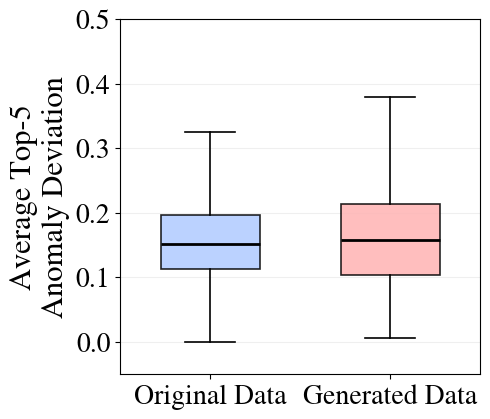

Original  mean: 0.1655, median: 0.1514
Generated mean: 0.1647, median: 0.1570
Original  Q1: 0.1120, Q3: 0.1969
Generated Q1: 0.1035, Q3: 0.2137



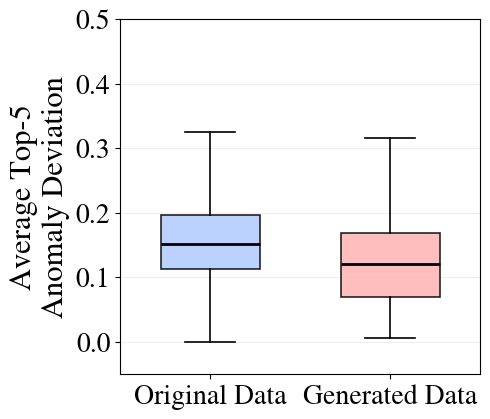

Original  mean: 0.1655, median: 0.1514
Generated mean: 0.1232, median: 0.1207
Original  Q1: 0.1120, Q3: 0.1969
Generated Q1: 0.0687, Q3: 0.1679



In [14]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

PLOT_DIR = "../../../Analysis/Plot/Appendix/anomalypreserve"
radius = 3
top_n = 5

def to_2d_r(arr):
    arr = np.asarray(arr, dtype=float)
    if arr.ndim == 3 and arr.shape[-1] == 1:
        arr = arr.squeeze(-1)
    return arr

def surrounding_median_baseline(data, radius=2):
    data = np.asarray(data, dtype=float)
    if data.ndim != 2:
        raise ValueError("data must be a 2D array.")
    if radius < 1:
        raise ValueError("radius must be at least 1.")
    window_size = 2 * radius + 1
    padded = np.pad(data, pad_width=((0, 0), (radius, radius)), mode="edge")
    windows = sliding_window_view(padded, window_shape=window_size, axis=1)
    surrounding_values = np.concatenate(
        [windows[:, :, :radius], windows[:, :, radius + 1:]],
        axis=-1,
    )
    return np.nanmedian(surrounding_values, axis=-1)

def top_n_mean(values, n=5):
    values = np.asarray(values, dtype=float)
    if values.ndim != 2:
        raise ValueError("values must be a 2D array.")
    num_points = values.shape[1]
    if not 1 <= n <= num_points:
        raise ValueError(f"n must be between 1 and {num_points}.")
    safe_values = np.where(np.isfinite(values), values, -np.inf)
    top_values = np.partition(safe_values, kth=num_points - n, axis=1)[:, -n:]
    top_values[top_values == -np.inf] = np.nan
    return np.nanmean(top_values, axis=1)

def compute_top_n_local_deviation(data_2d, radius=5, top_n=10):
    baseline = surrounding_median_baseline(data_2d, radius=radius)
    abs_dev = np.abs(data_2d - baseline)
    top_n_dev = top_n_mean(abs_dev, n=top_n)
    return top_n_dev[np.isfinite(top_n_dev)]

def per_run_top_n_local_deviation(r_list, radius=3, top_n=5):
    """每个 run 单独计算 top-n local deviation，返回长度为 5 的 list。"""
    return [
        compute_top_n_local_deviation(to_2d_r(r), radius=radius, top_n=top_n)
        for r in r_list
    ]

def plot_topn_boxplot(ori_vals, gen_vals, top_n, title=None, save_path=None, ylim=None, showfliers=False):
    fig, ax = plt.subplots(figsize=(5, 4.2))
    box = ax.boxplot(
        [ori_vals, gen_vals],
        positions=[1, 2],
        widths=0.55,
        patch_artist=True,
        showfliers=showfliers,
        medianprops={"color": "black", "linewidth": 2.0},
        boxprops={"edgecolor": "black", "linewidth": 1.2},
        whiskerprops={"color": "black", "linewidth": 1.2},
        capprops={"color": "black", "linewidth": 1.2},
    )
    for patch, color in zip(box["boxes"], ["#AFCBFF", "#FFB3B3"]):
        patch.set_facecolor(color)
        patch.set_alpha(0.85)

    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Original Data", "Generated Data"], fontsize=22)
    ax.set_ylabel(f"Average Top-{top_n}\nAnomaly Deviation", fontsize=22)
    ax.tick_params(axis="both", labelsize=20)
    ax.grid(axis="y", alpha=0.2)
    if ylim is not None:
        ax.set_ylim(ylim)
    if title is not None:
        ax.set_title(title, fontsize=18)

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Original  mean: {np.mean(ori_vals):.4f}, median: {np.median(ori_vals):.4f}")
    print(f"Generated mean: {np.mean(gen_vals):.4f}, median: {np.median(gen_vals):.4f}")
    print(f"Original  Q1: {np.percentile(ori_vals, 25):.4f}, Q3: {np.percentile(ori_vals, 75):.4f}")
    print(f"Generated Q1: {np.percentile(gen_vals, 25):.4f}, Q3: {np.percentile(gen_vals, 75):.4f}\n")

# ---------- 每个 run 单独保存 residual（长度均为 5）----------
ori_runs = [globals()[f"r_ori{i}"] for i in range(1, 6)]
gen_diff_runs = [globals()[f"r_gen{i}1"] for i in range(1, 6)]   # DiffusionTS
gen_cn_runs = [globals()[f"r_gen{i}2"] for i in range(1, 6)]    # ControlNet
gen_heavy_runs = [globals()[f"r_gen{i}3"] for i in range(1, 6)] # Heavy
gen_heavy_cn_runs = [globals()[f"r_gen{i}4"] for i in range(1, 6)]  # Heavy ControlNet

ori_top_n_deviation = per_run_top_n_local_deviation(ori_runs, radius=radius, top_n=top_n)
gen_diff_top_n_deviation = per_run_top_n_local_deviation(gen_diff_runs, radius=radius, top_n=top_n)
gen_cn_top_n_deviation = per_run_top_n_local_deviation(gen_cn_runs, radius=radius, top_n=top_n)
gen_heavy_top_n_deviation = per_run_top_n_local_deviation(gen_heavy_runs, radius=radius, top_n=top_n)
gen_heavy_cn_top_n_deviation = per_run_top_n_local_deviation(gen_heavy_cn_runs, radius=radius, top_n=top_n)

# ---------- 自选 run 索引 [0]~[4] 画图 ----------
# 0 -> power1, 1 -> power2, ..., 4 -> power5

# 示例：power1, Original vs DiffusionTS
plot_topn_boxplot(
    ori_top_n_deviation[0],
    gen_heavy_cn_top_n_deviation[0],
    top_n=top_n,
    ylim=(-0.05, 0.5),
    showfliers=False,
    save_path=f"{PLOT_DIR}/anomaly_deviation_boxplot_controlnet.png",
)

# 示例：power3, Original vs Heavy ControlNet
plot_topn_boxplot(
    ori_top_n_deviation[0],
    gen_heavy_top_n_deviation[0],
    top_n=top_n,
    ylim=(-0.05, 0.5),
    showfliers=False,
    save_path=f"{PLOT_DIR}/anomaly_deviation_boxplot_diffusionTS.png",
)

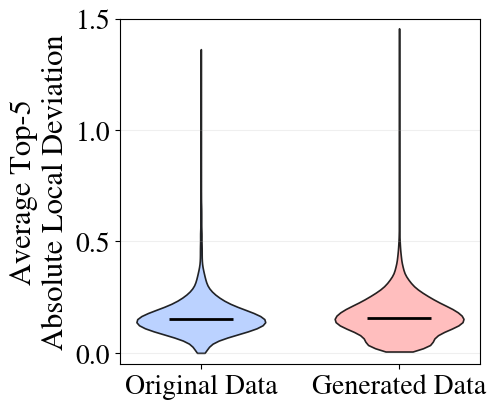

===== Violin Plot Summary =====
Original mean: 0.1655, median: 0.1514
Generated mean: 0.1647, median: 0.1570
Original Q1: 0.1120, Q3: 0.1969
Generated Q1: 0.1035, Q3: 0.2137



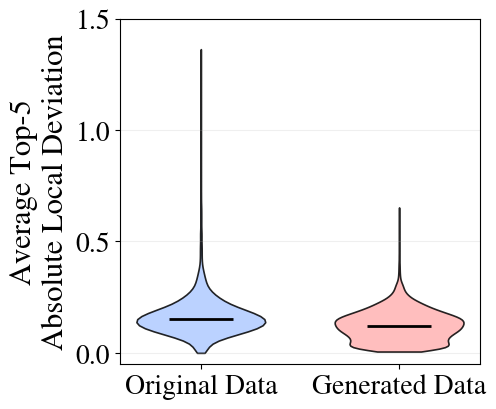

===== Violin Plot Summary =====
Original mean: 0.1655, median: 0.1514
Generated mean: 0.1232, median: 0.1207
Original Q1: 0.1120, Q3: 0.1969
Generated Q1: 0.0687, Q3: 0.1679



In [18]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

PLOT_DIR = "../../../Analysis/Plot/Appendix/anomalypreserve"
radius = 3
top_n = 5

def to_2d_r(arr):
    arr = np.asarray(arr, dtype=float)
    if arr.ndim == 3 and arr.shape[-1] == 1:
        arr = arr.squeeze(-1)
    return arr

def surrounding_median_baseline(data, radius=2):
    data = np.asarray(data, dtype=float)
    if data.ndim != 2:
        raise ValueError("data must be a 2D array.")
    if radius < 1:
        raise ValueError("radius must be at least 1.")
    window_size = 2 * radius + 1
    padded = np.pad(data, pad_width=((0, 0), (radius, radius)), mode="edge")
    windows = sliding_window_view(padded, window_shape=window_size, axis=1)
    surrounding_values = np.concatenate(
        [windows[:, :, :radius], windows[:, :, radius + 1:]],
        axis=-1,
    )
    return np.nanmedian(surrounding_values, axis=-1)

def top_n_mean(values, n=5):
    values = np.asarray(values, dtype=float)
    if values.ndim != 2:
        raise ValueError("values must be a 2D array.")
    num_points = values.shape[1]
    if not 1 <= n <= num_points:
        raise ValueError(f"n must be between 1 and {num_points}.")
    safe_values = np.where(np.isfinite(values), values, -np.inf)
    top_values = np.partition(safe_values, kth=num_points - n, axis=1)[:, -n:]
    top_values[top_values == -np.inf] = np.nan
    return np.nanmean(top_values, axis=1)

def compute_top_n_local_deviation(data_2d, radius=5, top_n=10):
    baseline = surrounding_median_baseline(data_2d, radius=radius)
    abs_dev = np.abs(data_2d - baseline)
    top_n_dev = top_n_mean(abs_dev, n=top_n)
    return top_n_dev[np.isfinite(top_n_dev)]

def per_run_top_n_local_deviation(r_list, radius=3, top_n=5):
    """每个 run 单独计算 top-n local deviation，返回长度为 5 的 list。"""
    return [
        compute_top_n_local_deviation(to_2d_r(r), radius=radius, top_n=top_n)
        for r in r_list
    ]

def plot_topn_violin(ori_vals, gen_vals, top_n, title=None, save_path=None, ylim=None, bw_method=None):
    fig, ax = plt.subplots(figsize=(5, 4.2))
    violin = ax.violinplot(
        [ori_vals, gen_vals],
        positions=[1, 2],
        widths=0.65,
        showmeans=False,
        showmedians=True,
        showextrema=False,
        bw_method=bw_method,
    )
    for body, color in zip(violin["bodies"], ["#AFCBFF", "#FFB3B3"]):
        body.set_facecolor(color)
        body.set_edgecolor("black")
        body.set_linewidth(1.2)
        body.set_alpha(0.85)
    violin["cmedians"].set_color("black")
    violin["cmedians"].set_linewidth(2.0)

    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Original Data", "Generated Data"], fontsize=22)
    ax.set_ylabel(f"Average Top-{top_n}\nAbsolute Local Deviation", fontsize=22)
    ax.tick_params(axis="both", labelsize=20)
    ax.grid(axis="y", alpha=0.2)
    if ylim is not None:
        ax.set_ylim(ylim)
    if title is not None:
        ax.set_title(title, fontsize=18)

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("===== Violin Plot Summary =====")
    print(f"Original mean: {np.mean(ori_vals):.4f}, median: {np.median(ori_vals):.4f}")
    print(f"Generated mean: {np.mean(gen_vals):.4f}, median: {np.median(gen_vals):.4f}")
    print(f"Original Q1: {np.percentile(ori_vals, 25):.4f}, Q3: {np.percentile(ori_vals, 75):.4f}")
    print(f"Generated Q1: {np.percentile(gen_vals, 25):.4f}, Q3: {np.percentile(gen_vals, 75):.4f}\n")

# ---------- 每个 run 单独保存 residual（长度均为 5）----------
ori_runs = [globals()[f"r_ori{i}"] for i in range(1, 6)]
gen_diff_runs = [globals()[f"r_gen{i}1"] for i in range(1, 6)]   # DiffusionTS
gen_cn_runs = [globals()[f"r_gen{i}2"] for i in range(1, 6)]    # ControlNet
gen_heavy_runs = [globals()[f"r_gen{i}3"] for i in range(1, 6)] # Heavy
gen_heavy_cn_runs = [globals()[f"r_gen{i}4"] for i in range(1, 6)]  # Heavy ControlNet

ori_top_n_deviation = per_run_top_n_local_deviation(ori_runs, radius=radius, top_n=top_n)
gen_diff_top_n_deviation = per_run_top_n_local_deviation(gen_diff_runs, radius=radius, top_n=top_n)
gen_cn_top_n_deviation = per_run_top_n_local_deviation(gen_cn_runs, radius=radius, top_n=top_n)
gen_heavy_top_n_deviation = per_run_top_n_local_deviation(gen_heavy_runs, radius=radius, top_n=top_n)
gen_heavy_cn_top_n_deviation = per_run_top_n_local_deviation(gen_heavy_cn_runs, radius=radius, top_n=top_n)

# ---------- 自选 run 索引 [0]~[4] 画图 ----------
# 0 -> power1, 1 -> power2, ..., 4 -> power5

# 示例：power1, Original vs DiffusionTS

# 示例：power1, Original vs DiffusionTS
plot_topn_violin(
    ori_top_n_deviation[0],
    gen_heavy_cn_top_n_deviation[0],
    top_n=top_n,
    ylim=(-0.05, 1.5),
    bw_method=0.2,
    save_path=f"{PLOT_DIR}/anomaly_deviation_violinplot_controlnet.png",
)

# 示例：power3, Original vs Heavy ControlNet
plot_topn_violin(
    ori_top_n_deviation[0],
    gen_heavy_top_n_deviation[0],
    top_n=top_n,
    ylim=(-0.05, 1.5),
    bw_method=0.2,
    save_path=f"{PLOT_DIR}/anomaly_deviation_violinplot_diffusionTS.png",
)